In [5]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

file_path = r"C:\Users\RUTHVIK REDDY\lulc_project\NDVI results\NDVI Results - Sheet1.csv"
df = pd.read_csv(file_path)

print("Columns in your CSV:")
print(df.columns.tolist())
print("\nFirst 5 rows:")
print(df.head())



Columns in your CSV:
['Year', '0_1_Zone_mean', '1_3_Zone_mean', '3_5_Zone_mean', 'Overall_mean']

First 5 rows:
   Year  0_1_Zone_mean  1_3_Zone_mean  3_5_Zone_mean  Overall_mean
0  2004       0.161299       0.165083       0.167274      0.164552
1  2005       0.146595       0.153780       0.150772      0.150383
2  2006       0.144685       0.147854       0.144514      0.145684
3  2007       0.141404       0.145131       0.143683      0.143406
4  2008       0.129747       0.139144       0.137614      0.135502


In [6]:
df["Year"] = pd.to_numeric(df["Year"], errors="coerce")
df = df[df["Year"].between(2005, 2025)].copy()
df = df.sort_values("Year")

zone_columns = {
    "0–1 km zone": "0_1_Zone_mean",
    "1–3 km zone": "1_3_Zone_mean",
    "3–5 km zone": "3_5_Zone_mean",
}
overall_column = "Overall_mean"


In [7]:
# Ensure NDVI columns are numeric
for col in list(zone_columns.values()) + [overall_column]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Calculate anomalies relative to each column's 2005–2025 mean
anomaly_df = df[["Year"]].copy()
reference_means = {}

for label, col in zone_columns.items():
    reference_mean = df[col].mean()
    reference_means[label] = reference_mean
    anomaly_df[f"{label} anomaly"] = df[col] - reference_mean

In [8]:
# Also calculate overall anomaly for the output CSV (not plotted by default)
overall_mean = df[overall_column].mean()
reference_means["Overall"] = overall_mean
anomaly_df["Overall anomaly"] = df[overall_column] - overall_mean

# Save anomaly values and reference-period means to the same folder as the input CSV
out_dir = Path(file_path).resolve().parent
out_dir.mkdir(parents=True, exist_ok=True)
anomaly_csv = out_dir / "NDVI_Anomalies_2005_2025.csv"
means_csv = out_dir / "NDVI_Anomaly_Reference_Means_2005_2025.csv"
anomaly_df.to_csv(anomaly_csv, index=False)
pd.DataFrame(
    [{"Zone": zone, "Reference mean NDVI (2005–2025)": mean}
     for zone, mean in reference_means.items()]
).to_csv(means_csv, index=False)


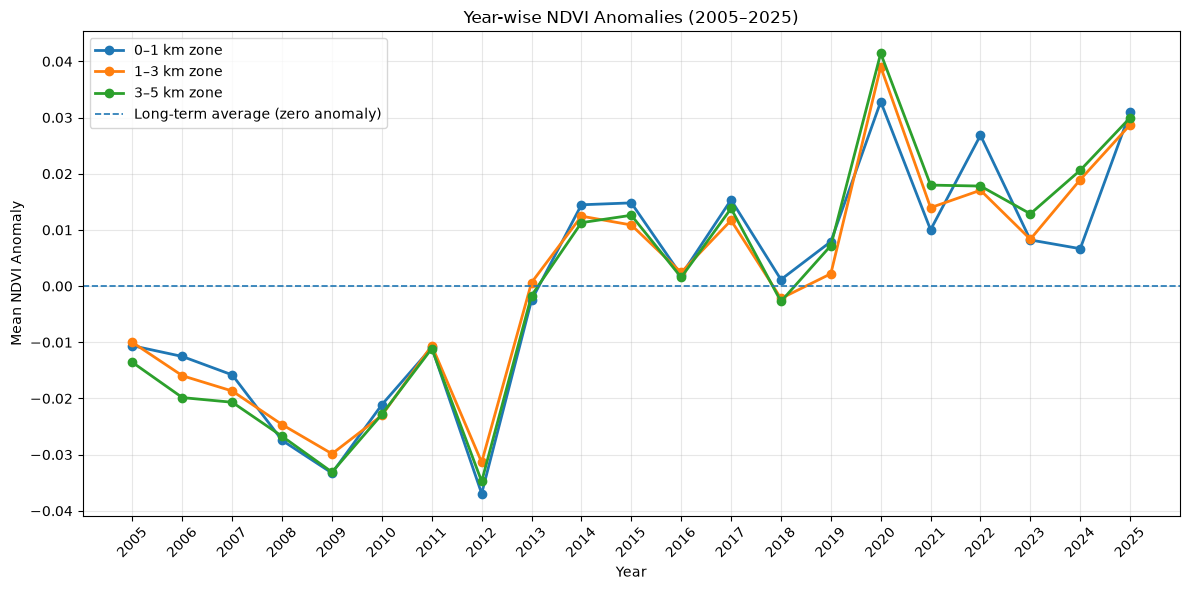


Reference-period mean NDVI:
0–1 km zone: 0.157213
1–3 km zone: 0.163809
3–5 km zone: 0.164362
Overall: 0.161795

Anomaly CSV saved to: C:\Users\RUTHVIK REDDY\lulc_project\NDVI results\NDVI_Anomalies_2005_2025.csv
Reference means CSV saved to: C:\Users\RUTHVIK REDDY\lulc_project\NDVI results\NDVI_Anomaly_Reference_Means_2005_2025.csv
Graph saved to: C:\Users\RUTHVIK REDDY\lulc_project\NDVI results\NDVI_Anomalies_2005_2025.png


In [9]:
# Plot zone-wise anomaly time series
plt.figure(figsize=(12, 6))
for label in zone_columns:
    plt.plot(
        anomaly_df["Year"],
        anomaly_df[f"{label} anomaly"],
        marker="o",
        linewidth=2,
        label=label
    )

plt.axhline(0, linewidth=1.2, linestyle="--", label="Long-term average (zero anomaly)")
plt.title("Year-wise NDVI Anomalies (2005–2025)")
plt.xlabel("Year")
plt.ylabel("Mean NDVI Anomaly")
plt.xticks(range(2005, 2026, 1), rotation=45)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

plot_path = out_dir / "NDVI_Anomalies_2005_2025.png"
plt.savefig(plot_path, dpi=300, bbox_inches="tight")
plt.show()

print("\nReference-period mean NDVI:")
for zone, mean in reference_means.items():
    print(f"{zone}: {mean:.6f}")

print(f"\nAnomaly CSV saved to: {anomaly_csv}")
print(f"Reference means CSV saved to: {means_csv}")
print(f"Graph saved to: {plot_path}")